In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score
from sklearn.utils import resample

from google.colab import drive

In [50]:
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

In [51]:
uploaded = drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
df_data = pd.read_csv("/content/drive/MyDrive/dataset/penguins/penguins.csv")

### Exploratory Data Analysis (EDA)

In [53]:
df_data.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [54]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [55]:
df_data.shape

(344, 8)

In [56]:
df_data.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [57]:
df_data = df_data.dropna()
df_data.isna().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0
year,0


In [58]:
df_data.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,333.000000,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057,2008.042042
std,5.468668,1.969235,14.015765,805.215802,0.812944
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.500000,15.600000,190.000000,3550.000000,2007.000000
50%,44.500000,17.300000,197.000000,4050.000000,2008.000000
75%,48.600000,18.700000,213.000000,4775.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [59]:
df_data.shape

(333, 8)

In [60]:
df_data.groupby("species").size()

,0
species,
Adelie,146
Chinstrap,68
Gentoo,119


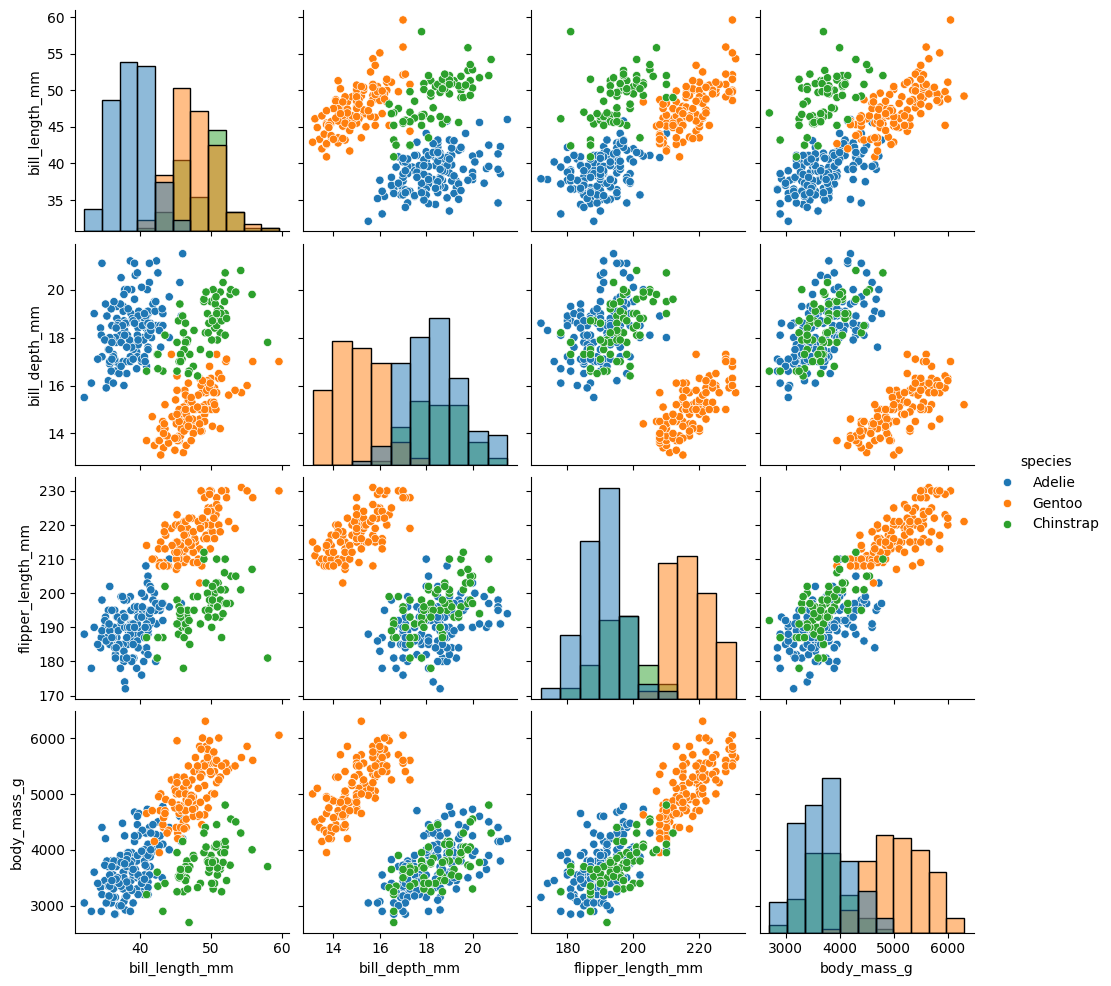

In [61]:
num_col = df_data.select_dtypes(include=["number"]).columns
num_col = num_col.drop("year")

pairplot = sns.pairplot(df_data, vars=num_col, hue="species", diag_kind="hist")
plt.show()

### PREPROCESSING

In [62]:
X = df_data[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y = df_data["species"]

In [63]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### MODELLING

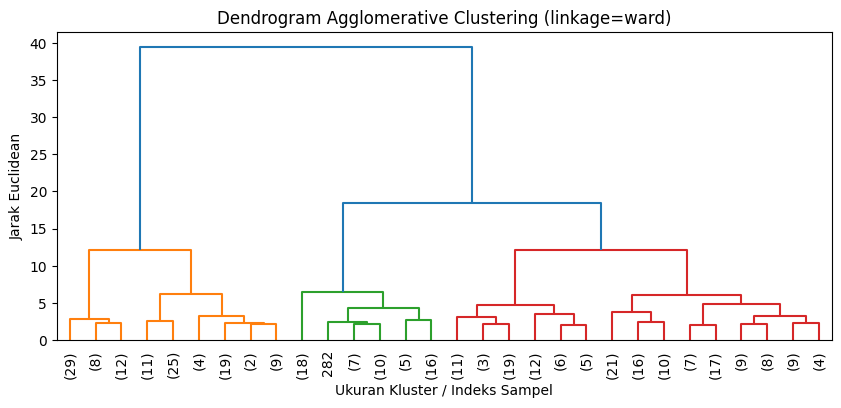

In [64]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)

plt.figure(figsize=(10, 4))
z = linkage(X_scaled, method='ward')
dendrogram(z,
           truncate_mode='lastp',
           p=30,
           leaf_rotation=90.,
           leaf_font_size=10.,
           color_threshold=15)

plt.title("Dendrogram Agglomerative Clustering (linkage=ward)")
plt.xlabel("Ukuran Kluster / Indeks Sampel")
plt.ylabel("Jarak Euclidean")
plt.show()

In [65]:
eps_values = [0.1 + 0.1 * i for i in range(10)]

for eps in eps_values:
  dbscan = DBSCAN(eps=eps, min_samples=5)
  labels = dbscan.fit_predict(X_scaled)

  n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
  n_noise = list(labels).count(-1)

  print(f"eps = {eps:.1f} jumlah cluster: {n_clusters}, jumlah titik noise: {n_noise}")

dbscan_default = DBSCAN(eps=0.5, min_samples=5)
labels_dbscan = dbscan_default.fit_predict(X_scaled)

eps = 0.1 jumlah cluster: 0, jumlah titik noise: 333
eps = 0.2 jumlah cluster: 0, jumlah titik noise: 333
eps = 0.3 jumlah cluster: 3, jumlah titik noise: 315
eps = 0.4 jumlah cluster: 12, jumlah titik noise: 169
eps = 0.5 jumlah cluster: 4, jumlah titik noise: 66
eps = 0.6 jumlah cluster: 2, jumlah titik noise: 32
eps = 0.7 jumlah cluster: 2, jumlah titik noise: 17
eps = 0.8 jumlah cluster: 2, jumlah titik noise: 5
eps = 0.9 jumlah cluster: 2, jumlah titik noise: 2
eps = 1.0 jumlah cluster: 2, jumlah titik noise: 1


In [66]:
gmm = GaussianMixture(n_components=3, random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

In [67]:
spectral = SpectralClustering(n_clusters=3, affinity='nearest_neighbors', random_state=42)
labels_spectral = spectral.fit_predict(X_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


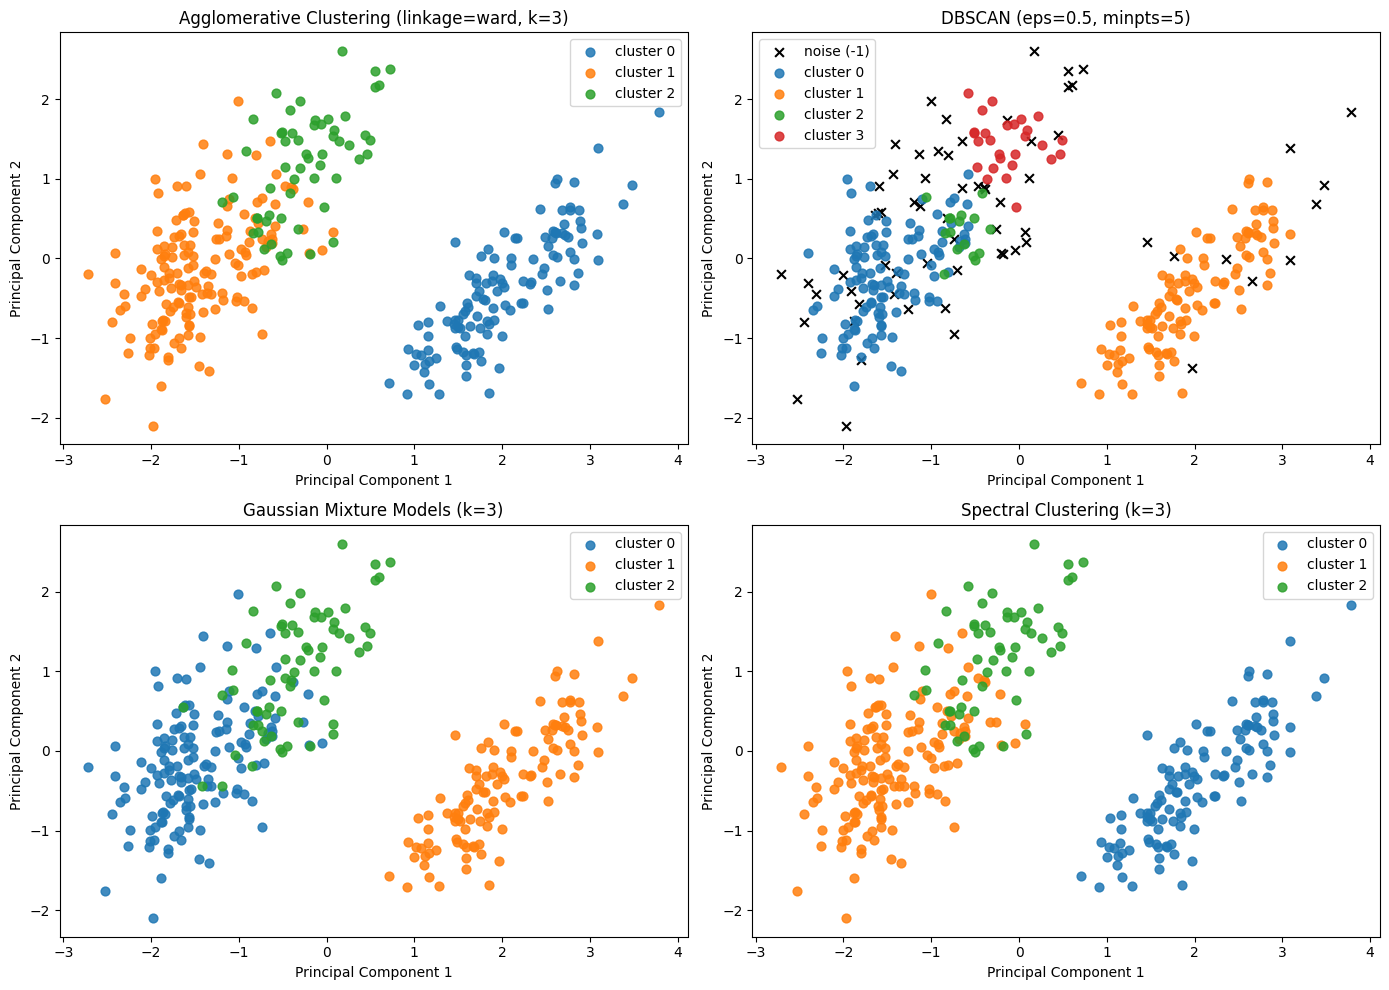

In [68]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(2, 2, figsize=(2 * 7, 2 * 5))
axes = axes.flatten()

models = [
  ("Agglomerative Clustering (linkage=ward, k=3)", labels_agg),
  ("DBSCAN (eps=0.5, minpts=5)", labels_dbscan),
  ("Gaussian Mixture Models (k=3)", labels_gmm),
  ("Spectral Clustering (k=3)", labels_spectral)
]

for ax, (title, labels) in zip(axes, models):
  unique_labels = sorted(set(labels))

  for label in unique_labels:
    mask = (labels == label)

    if label == -1:
      ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c='black', marker='x', s=40, label='noise (-1)')
    else:
      ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=40, alpha=0.85, label=f'cluster {label}')

  ax.set_title(title)
  ax.set_xlabel("Principal Component 1")
  ax.set_ylabel("Principal Component 2")
  ax.legend()

plt.tight_layout()
plt.show()

### EVALUATION

In [69]:
full_results = []

models_full = [
  ("Agglomerative Clustering (linkage=ward, k=3)", labels_agg),
  ("DBSCAN (eps=0.5, minpts=5)", labels_dbscan),
  ("Gaussian Mixture Models (k=3)", labels_gmm),
  ("Spectral Clustering (k=3)", labels_spectral)
]

for name, labels in models_full:
  silhouette = np.nan

  if "DBSCAN" in name:
    non_noise_mask = (labels != -1)
    n_noise_removed = np.sum(~non_noise_mask)

    if len(set(labels[non_noise_mask])) > 1:
      silhouette = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])

  else:
    n_noise_removed = 0
    silhouette = silhouette_score(X_scaled, labels)

  rand_idx = rand_score(y, labels)
  nmi = normalized_mutual_info_score(y, labels)

  full_results.append({
    "model": name,
    "silhouette": silhouette,
    "n_noise_removed": n_noise_removed,
    "rand_idx": rand_idx,
    "nmi": nmi
  })

df_full = pd.DataFrame(full_results)

In [70]:
stability_records = {name: {"silhouette": [], "rand_idx": [], "nmi": []} for name, _ in models_full}
seeds = [17, 67, 76]

for seed in seeds:
  X_sub, y_sub = resample(X_scaled, y, replace=False, n_samples=int(0.9 * len(X_scaled)), random_state=seed)

  sub_preds = {
    "Agglomerative Clustering (linkage=ward, k=3)": AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_sub),
    "DBSCAN (eps=0.5, minpts=5)": DBSCAN(eps=0.5, min_samples=5).fit_predict(X_sub),
    "Gaussian Mixture Models (k=3)": GaussianMixture(n_components=3, random_state=42).fit_predict(X_sub),
    "Spectral Clustering (k=3)": SpectralClustering(n_clusters=3, affinity='nearest_neighbors', random_state=42).fit_predict(X_sub)
  }

  for name, sub_label in sub_preds.items():

    if "DBSCAN" in name:
      mask = (sub_label != -1)
      silhouette_sub = silhouette_score(X_sub[mask], sub_label[mask]) if len(set(sub_label[mask])) > 1 else np.nan

    else:
      silhouette_sub = silhouette_score(X_sub, sub_label)

    stability_records[name]["silhouette"].append(silhouette_sub)
    stability_records[name]["rand_idx"].append(rand_score(y_sub, sub_label))
    stability_records[name]["nmi"].append(normalized_mutual_info_score(y_sub, sub_label))

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [76]:
stability_summary = []

for name in stability_records:
  stability_summary.append({
    "model": name,
    "silhouette (90% Mean, Std)": f"{np.nanmean(stability_records[name]["silhouette"]):.4f}, {np.nanstd(stability_records[name]["silhouette"]):.4f}",
    "rand index (90% Mean, Std)": f"{np.mean(stability_records[name]["rand_idx"]):.4f}, {np.std(stability_records[name]["rand_idx"]):.4f}",
    "nmi (90% Mean, Std)": f"{np.mean(stability_records[name]["nmi"]):.4f}, {np.std(stability_records[name]["nmi"]):.4f}"
  })

df_stability = pd.DataFrame(stability_summary)
df_comparison = pd.merge(df_full, df_stability, on="model")

display(df_comparison.round(4))

,model,silhouette,n_noise_removed,rand_idx,nmi,"silhouette (90% Mean, Std)","rand index (90% Mean, Std)","nmi (90% Mean, Std)"
0,"Agglomerative Clustering (linkage=ward, k=3)",0.4521,0,0.9596,0.8989,"0.4489, 0.0089","0.9752, 0.0118","0.9292, 0.0231"
1,"DBSCAN (eps=0.5, minpts=5)",0.4223,66,0.8532,0.6634,"0.4318, 0.0005","0.8413, 0.0017","0.6544, 0.0089"
2,Gaussian Mixture Models (k=3),0.4527,0,0.9811,0.9337,"0.4434, 0.0079","0.9059, 0.1032","0.8418, 0.1211"
3,Spectral Clustering (k=3),0.4530,0,0.9596,0.8989,"0.4539, 0.0037","0.9657, 0.0100","0.9112, 0.0200"
